# 05 - Common evaluation (WP4), the five Midterm questions (WP5), error analysis (WP6)
All numbers are recomputed from saved probabilities. Thresholds other than 0.5 are fitted on validation and
frozen before test.

> **Dataset licence.** ViGoEmotions is for non-commercial research/education only and must not be redistributed. Keep `data/` and `results/private/` out of any public repository; the tables in `results/tables/` contain only aggregates, ids and labels.

In [1]:
# ---- Setup: works both locally and on Google Colab --------------------------------
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # EDIT: folder on your Drive that contains src/, configs/, resources/ and data/{train,val,test}.csv
    PROJECT_DIR = "/content/drive/MyDrive/vigoemotions_midterm"
    os.chdir(PROJECT_DIR)
    subprocess.run("pip -q install -r requirements-colab.txt", shell=True, check=True)
    # Java is needed by VnCoreNLP (PhoBERT word segmentation); falls back to pyvi otherwise
    if subprocess.run("java -version", shell=True, capture_output=True).returncode != 0:
        subprocess.run("apt-get -qq install -y default-jre-headless > /dev/null", shell=True)
else:
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))
os.environ["PYTHONPATH"] = os.path.abspath("src") + os.pathsep + os.environ.get("PYTHONPATH", "")
print("project dir:", os.getcwd())

import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
T = lambda name: pd.read_csv(f"results/tables/{name}")          # noqa: E731
F = lambda name, w=900: display(Image(f"results/figures/{name}", width=w))  # noqa: E731

project dir: /Users/tam/Documents/projects/ATI/midterm


In [2]:
extra = " ".join(r for r in ["visobert", "visobert14gb", "cafebert", "phobert_large", "ensemble_3", "ensemble_all"]
                 if os.path.exists(f"results/runs/{r}/summary.json"))
!python -m vigo analyze --tfidf tfidf_lr --rnn bilstm --transformer phobert --extra {extra} > results/logs/analysis.log 2>&1
print(open("results/logs/analysis.log").read()[-3000:])

5           0.6266            0.6576            0.7029          0.1041          0.0763    [+0.042, +0.108]
       long                        >= 30 whitespace tokens        283             0.4731             0.5219           0.4136           0.4865            0.5768            0.6220          0.1633          0.1354    [+0.099, +0.172]
      emoji                                     >= 1 emoji        536             0.5441             0.6106           0.5308           0.6152            0.5896            0.6648          0.0588          0.0495    [+0.019, +0.077]
emoji_heavy                          >= 2 emoji characters        180             0.5570             0.6462           0.5307           0.6416            0.6186            0.7040          0.0879          0.0624    [+0.024, +0.105]
   emoticon                            >= 1 ASCII emoticon        236             0.4934             0.5981           0.4188           0.5561            0.6076            0.6956          0.1888          

## Main results (test, tau = 0.5) - all required metrics

In [3]:
display(T("main_results_test.csv").round(4))
display(T("main_results_val.csv").round(4))

,model,run,params,train_time_s,device,macro_f1,micro_f1,weighted_f1,samples_f1,macro_f1_27emo,hamming_loss,lrap,map_macro,subset_accuracy,macro_precision,macro_recall
0,TF-IDF + OvR LR,tfidf_lr,2136316,6.1,cpu,0.5419,0.5576,0.5606,0.5359,0.5544,0.0665,0.6900,0.5603,0.1650,0.4969,0.6003
1,BiLSTM,bilstm,5173712,1296.0,cpu,0.5122,0.5330,0.5278,0.5051,0.5230,0.0581,0.6677,0.5394,0.2090,0.5702,0.4693
2,PhoBERT-base-v2,phobert,134429212,3060.2,mps,0.6292,0.6461,0.6432,0.6276,0.6368,0.0472,0.7690,0.6842,0.2937,0.6461,0.6168
3,ViSoBERT,visobert,96996892,2468.0,mps,0.6133,0.6316,0.6293,0.6118,0.6219,0.0483,0.7549,0.6561,0.2869,0.6432,0.5889
4,ViSoBERT-14GB,visobert14gb,96996892,2511.3,mps,0.6204,0.6423,0.6377,0.6236,0.6279,0.0470,0.7765,0.6784,0.2985,0.6513,0.5988
5,Ensemble (3),ensemble_3,328422996,8039.5,cpu,0.6430,0.6636,0.6582,0.6364,0.6516,0.0429,0.7928,0.7103,0.3208,0.7003,0.6007


,model,run,params,train_time_s,device,macro_f1,micro_f1,weighted_f1,samples_f1,macro_f1_27emo,hamming_loss,lrap,map_macro,subset_accuracy,macro_precision,macro_recall
0,TF-IDF + OvR LR,tfidf_lr,2136316,6.1,cpu,0.5313,0.5501,0.5542,0.5271,0.5414,0.0676,0.6828,0.5534,0.1699,0.4940,0.5798
1,BiLSTM,bilstm,5173712,1296.0,cpu,0.5193,0.5447,0.5398,0.5161,0.5237,0.0572,0.6683,0.5325,0.2357,0.5832,0.4741
2,PhoBERT-base-v2,phobert,134429212,3060.2,mps,0.6320,0.6441,0.6412,0.6262,0.6385,0.0473,0.7696,0.6761,0.3049,0.6602,0.6118
3,ViSoBERT,visobert,96996892,2468.0,mps,0.6095,0.6234,0.6201,0.6022,0.6171,0.0485,0.7447,0.6470,0.2880,0.6581,0.5709
4,ViSoBERT-14GB,visobert14gb,96996892,2511.3,mps,0.6171,0.6327,0.6294,0.6098,0.6235,0.0479,0.7626,0.6720,0.3020,0.6606,0.5842
5,Ensemble (3),ensemble_3,328422996,8039.5,cpu,0.6409,0.6562,0.6508,0.6295,0.6474,0.0433,0.7856,0.7111,0.3306,0.7157,0.5857


## Per-label F1 (27 emotions + neutral)

In [4]:
display(T("per_label_f1.csv"))

,label,train_frequency,tier,test_support,f1_tfidf_lr,f1_bilstm,f1_phobert,f1_visobert,f1_visobert14gb,f1_ensemble_3
0,amusement,2868,head,374,0.7285,0.6857,0.7664,0.7414,0.7664,0.7770
1,excitement,824,mid,98,0.4589,0.3797,0.5816,0.5029,0.4667,0.5698
2,joy,1614,head,204,0.5523,0.5187,0.6123,0.6127,0.6118,0.6318
3,love,1175,head,143,0.6646,0.6737,0.7205,0.7483,0.7320,0.7639
4,desire,762,tail,80,0.4577,0.4000,0.5091,0.5399,0.5369,0.5563
5,optimism,1046,mid,142,0.6265,0.5938,0.7609,0.6768,0.7132,0.7444
6,caring,1062,head,150,0.5774,0.5560,0.6646,0.6892,0.6890,0.7095
7,pride,774,mid,86,0.6818,0.6494,0.7190,0.7051,0.7241,0.7285
8,admiration,883,mid,101,0.4978,0.4431,0.6396,0.6073,0.6400,0.6564
9,gratitude,765,mid,108,0.8455,0.8190,0.8598,0.8638,0.8778,0.8727


## Q1 - Which labels have the highest / lowest F1?

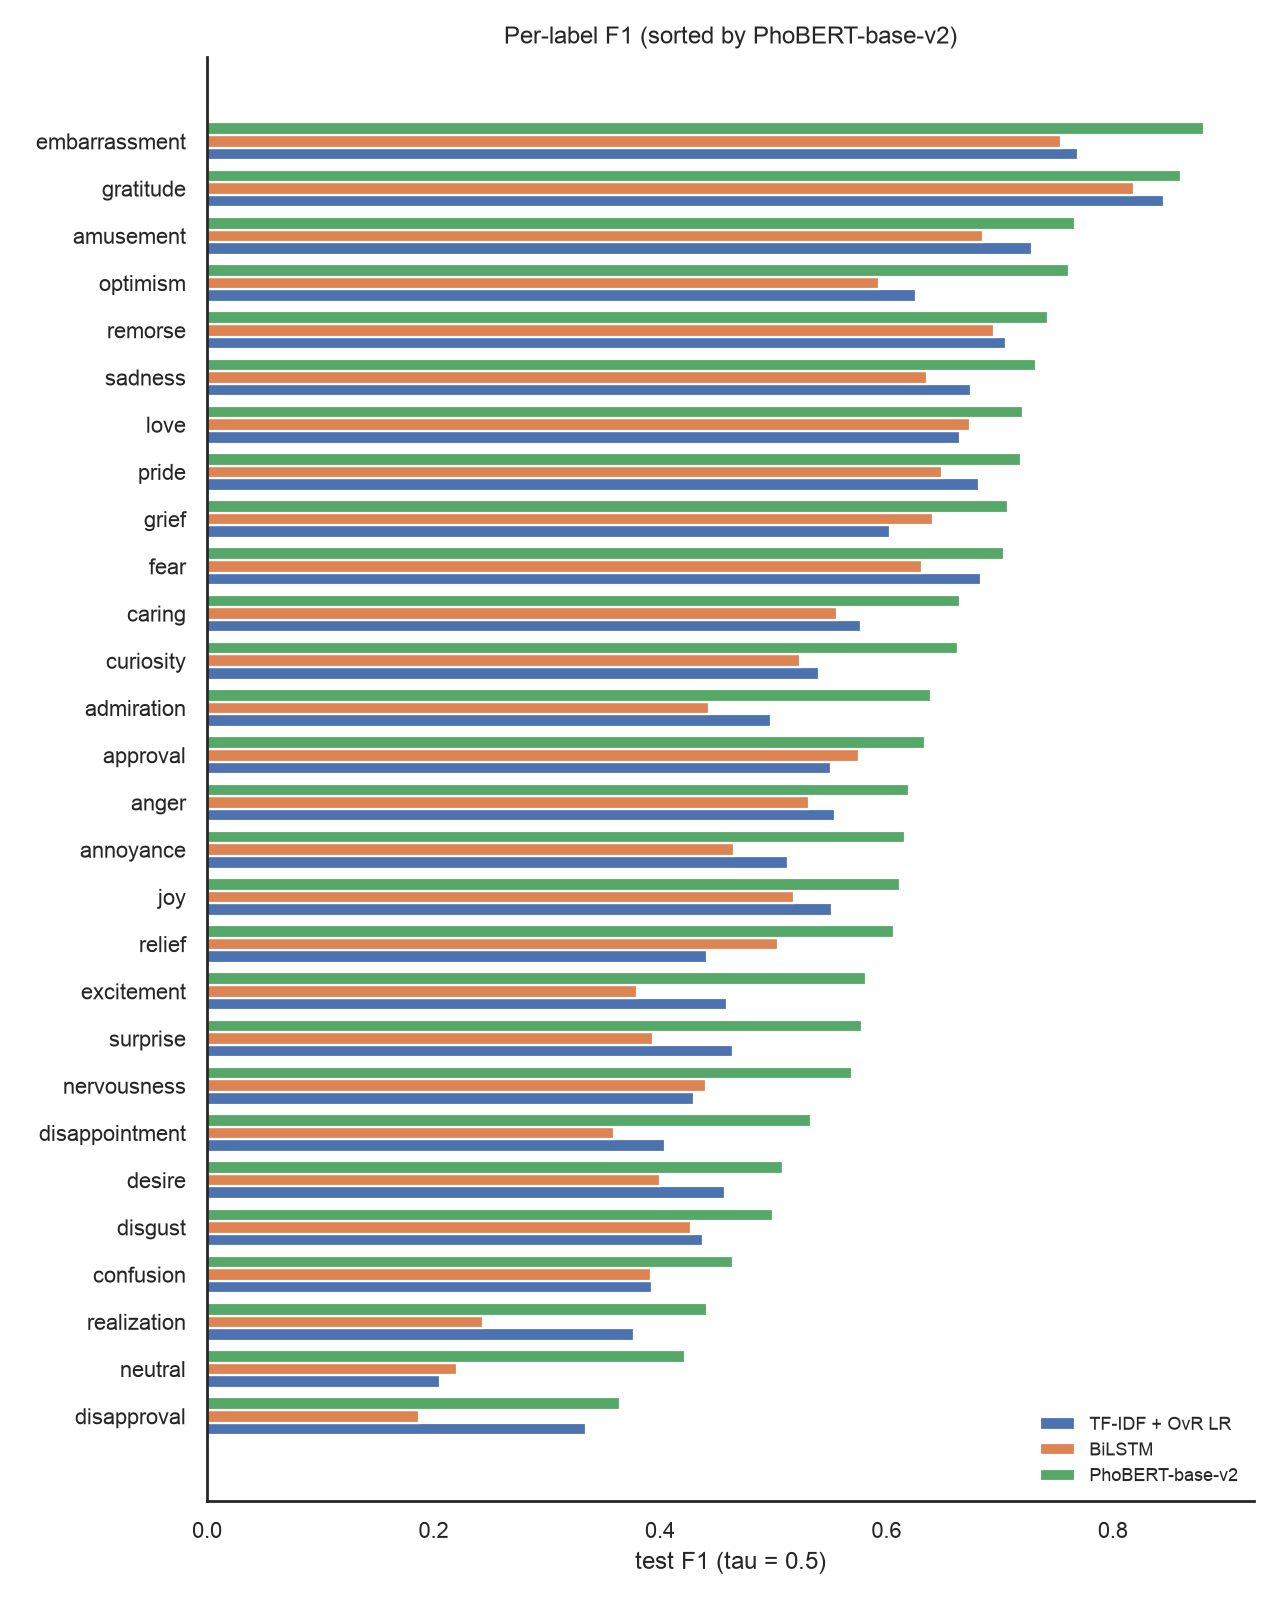

,model,position,rank,label,f1,train_frequency,tier
0,TF-IDF + OvR LR,top-5,1,gratitude,0.8455,765,mid
1,TF-IDF + OvR LR,top-5,2,embarrassment,0.7692,885,mid
2,TF-IDF + OvR LR,top-5,3,amusement,0.7285,2868,head
3,TF-IDF + OvR LR,top-5,4,remorse,0.7053,707,tail
4,TF-IDF + OvR LR,top-5,5,fear,0.6832,745,tail
5,TF-IDF + OvR LR,bottom-5,24,disappointment,0.4047,1522,head
6,TF-IDF + OvR LR,bottom-5,25,confusion,0.3933,676,tail
7,TF-IDF + OvR LR,bottom-5,26,realization,0.3768,687,tail
8,TF-IDF + OvR LR,bottom-5,27,disapproval,0.3345,969,mid
9,TF-IDF + OvR LR,bottom-5,28,neutral,0.2060,821,mid


In [5]:
F("q1_per_label_f1.png", 650)
display(T("q1_best_worst_labels.csv"))

## Q2 - Correlation between performance and training label frequency

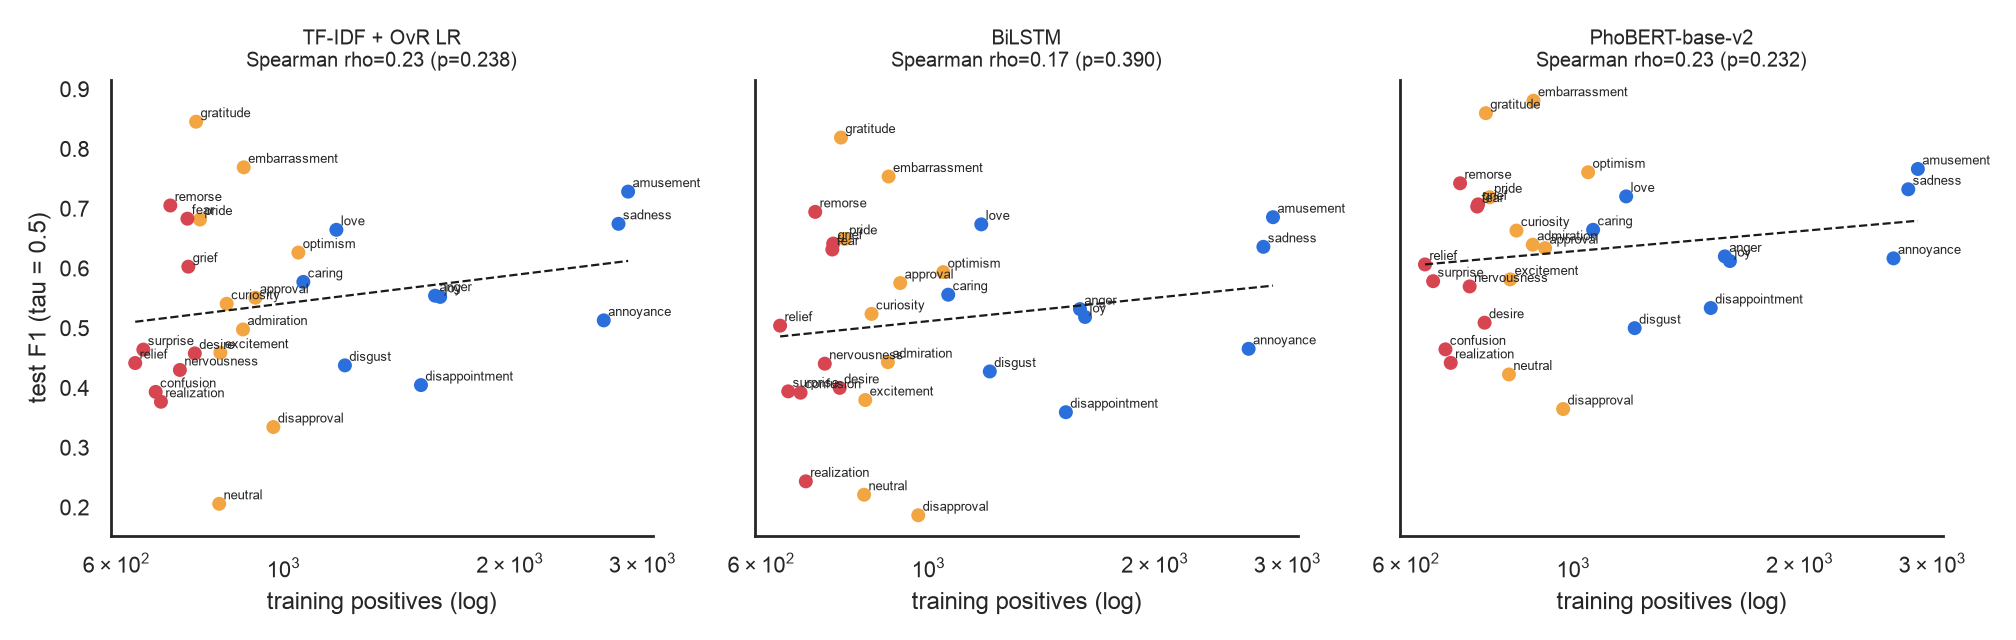

,model,pearson_r,pearson_p,pearson_r_logfreq,pearson_p_logfreq,spearman_rho,spearman_p,mean_f1_head,mean_f1_mid,mean_f1_tail
0,TF-IDF + OvR LR,0.221,0.258,0.205,0.296,0.230,0.238,0.567,0.551,0.506
1,BiLSTM,0.172,0.383,0.156,0.428,0.169,0.390,0.539,0.515,0.482
2,PhoBERT-base-v2,0.186,0.344,0.169,0.390,0.233,0.232,0.641,0.653,0.592


In [6]:
F("q2_frequency_vs_f1.png", 1000)
display(T("q2_frequency_correlation.csv").round(3))

## Q3 - Most frequent co-occurring pairs; does the model preserve them?

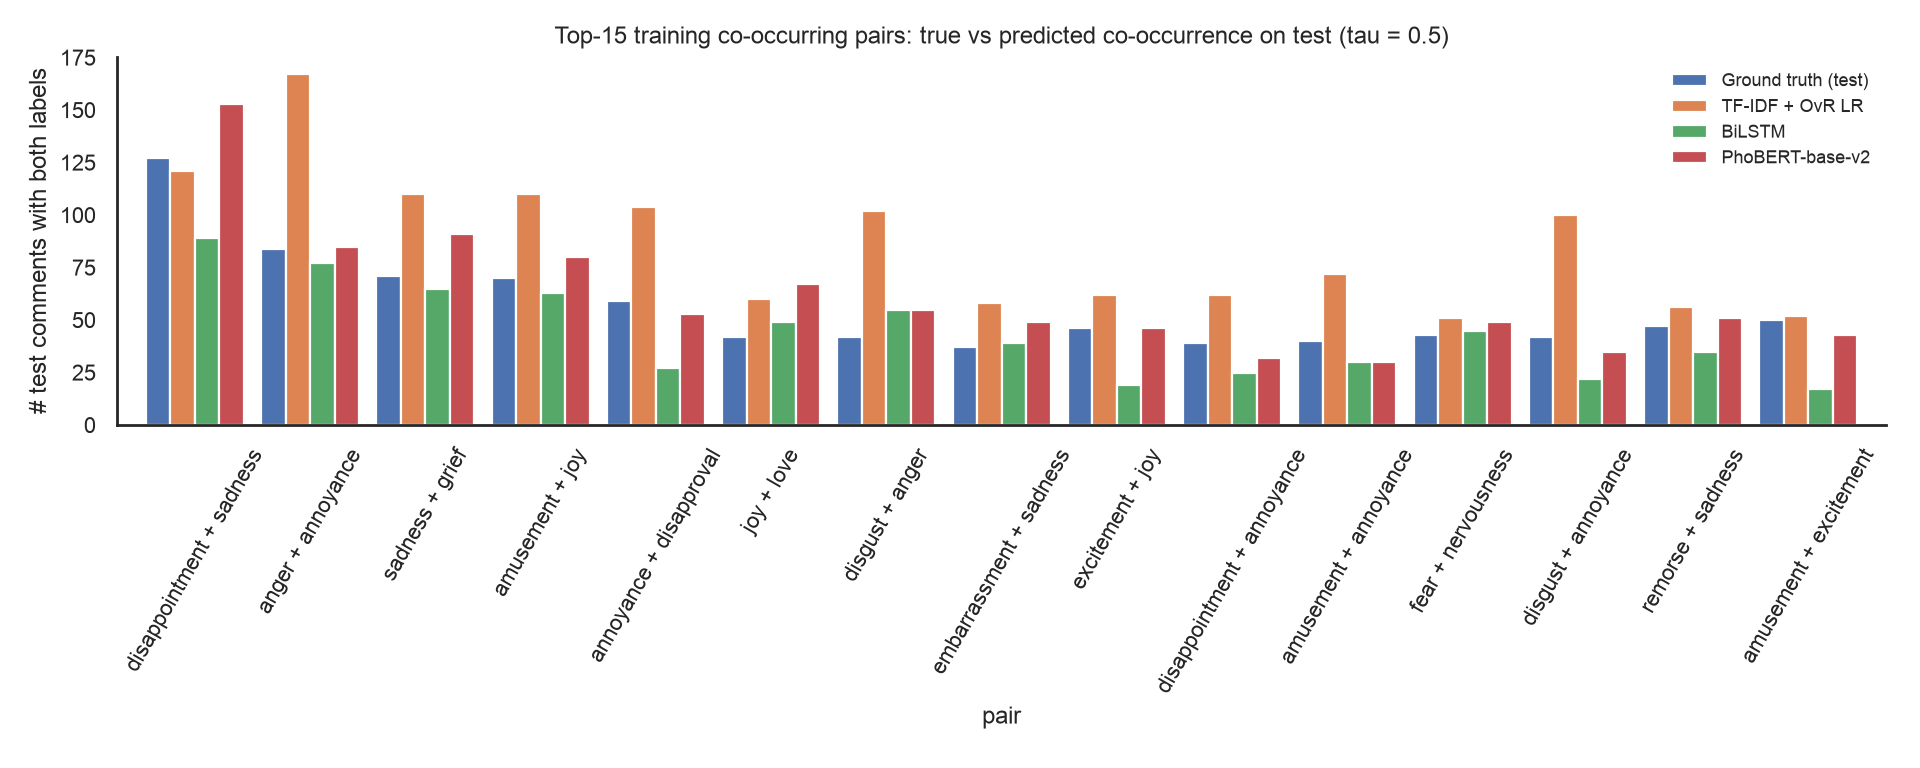

,model,pair,train_count,test_true_count,test_pred_count,pred/true,pair_recall
0,TF-IDF + OvR LR,disappointment + sadness,904,127,121,0.953,0.394
1,TF-IDF + OvR LR,anger + annoyance,699,84,167,1.988,0.488
2,TF-IDF + OvR LR,sadness + grief,620,71,110,1.549,0.718
3,TF-IDF + OvR LR,amusement + joy,568,70,110,1.571,0.557
4,TF-IDF + OvR LR,annoyance + disapproval,469,59,104,1.763,0.305
5,TF-IDF + OvR LR,joy + love,395,42,60,1.429,0.571
6,TF-IDF + OvR LR,disgust + anger,379,42,102,2.429,0.524
7,TF-IDF + OvR LR,embarrassment + sadness,366,37,58,1.568,0.811
8,TF-IDF + OvR LR,excitement + joy,359,46,62,1.348,0.457
9,TF-IDF + OvR LR,disappointment + annoyance,336,39,62,1.590,0.154


,model,"pearson(true_cooc, pred_cooc)","pearson(true_phi, pred_phi)","spearman(true_phi, pred_phi)",total_true_pairs,total_pred_pairs,mean_true_cardinality,mean_pred_cardinality
0,TF-IDF + OvR LR,0.921,0.918,0.844,2466,4698,1.907,2.304
1,BiLSTM,0.940,0.931,0.887,2466,1658,1.907,1.577
2,PhoBERT-base-v2,0.972,0.962,0.915,2466,2314,1.907,1.826


In [7]:
F("q3_cooccurrence_true_vs_pred.png", 1000)
display(T("q3_top_pairs_true_vs_pred.csv"))
display(T("q3_dependency_preservation.csv").round(3))

## Q4 - Text styles where PhoBERT beats the recurrent baseline

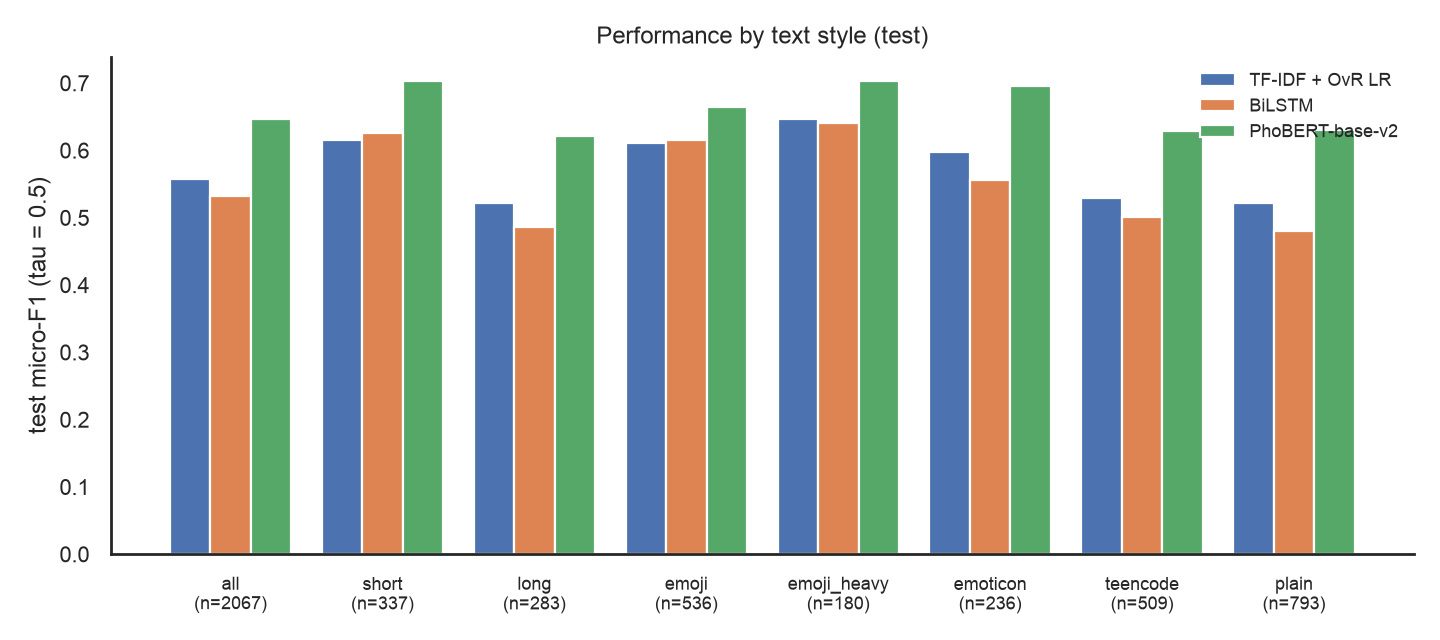

,subset,rule,n_samples,macro_f1_tfidf_lr,micro_f1_tfidf_lr,macro_f1_bilstm,micro_f1_bilstm,macro_f1_phobert,micro_f1_phobert,delta_macro_f1,delta_micro_f1,delta_micro_f1_ci95
0,all,all test comments,2067,0.5419,0.5576,0.5122,0.5330,0.6292,0.6461,0.1169,0.1131,"[+0.098, +0.128]"
1,short,<= 5 whitespace tokens,337,0.5753,0.6150,0.5535,0.6266,0.6576,0.7029,0.1041,0.0763,"[+0.042, +0.108]"
2,long,>= 30 whitespace tokens,283,0.4731,0.5219,0.4136,0.4865,0.5768,0.6220,0.1633,0.1354,"[+0.099, +0.172]"
3,emoji,>= 1 emoji,536,0.5441,0.6106,0.5308,0.6152,0.5896,0.6648,0.0588,0.0495,"[+0.019, +0.077]"
4,emoji_heavy,>= 2 emoji characters,180,0.5570,0.6462,0.5307,0.6416,0.6186,0.7040,0.0879,0.0624,"[+0.024, +0.105]"
5,emoticon,>= 1 ASCII emoticon,236,0.4934,0.5981,0.4188,0.5561,0.6076,0.6956,0.1888,0.1395,"[+0.099, +0.179]"
6,teencode,>= 1 multi-character teencode-dictionary token,509,0.5009,0.5301,0.4675,0.5006,0.5959,0.6290,0.1283,0.1284,"[+0.099, +0.155]"
7,plain,"not short, no emoji/emoticon/teencode",793,0.5257,0.5221,0.4857,0.4801,0.6277,0.6310,0.1420,0.1510,"[+0.128, +0.174]"


In [8]:
F("q4_text_style.png", 850)
display(T("q4_text_style_breakdown.csv").round(4))

## Q5 - Sensitivity to the default threshold 0.5 (validation sweep)

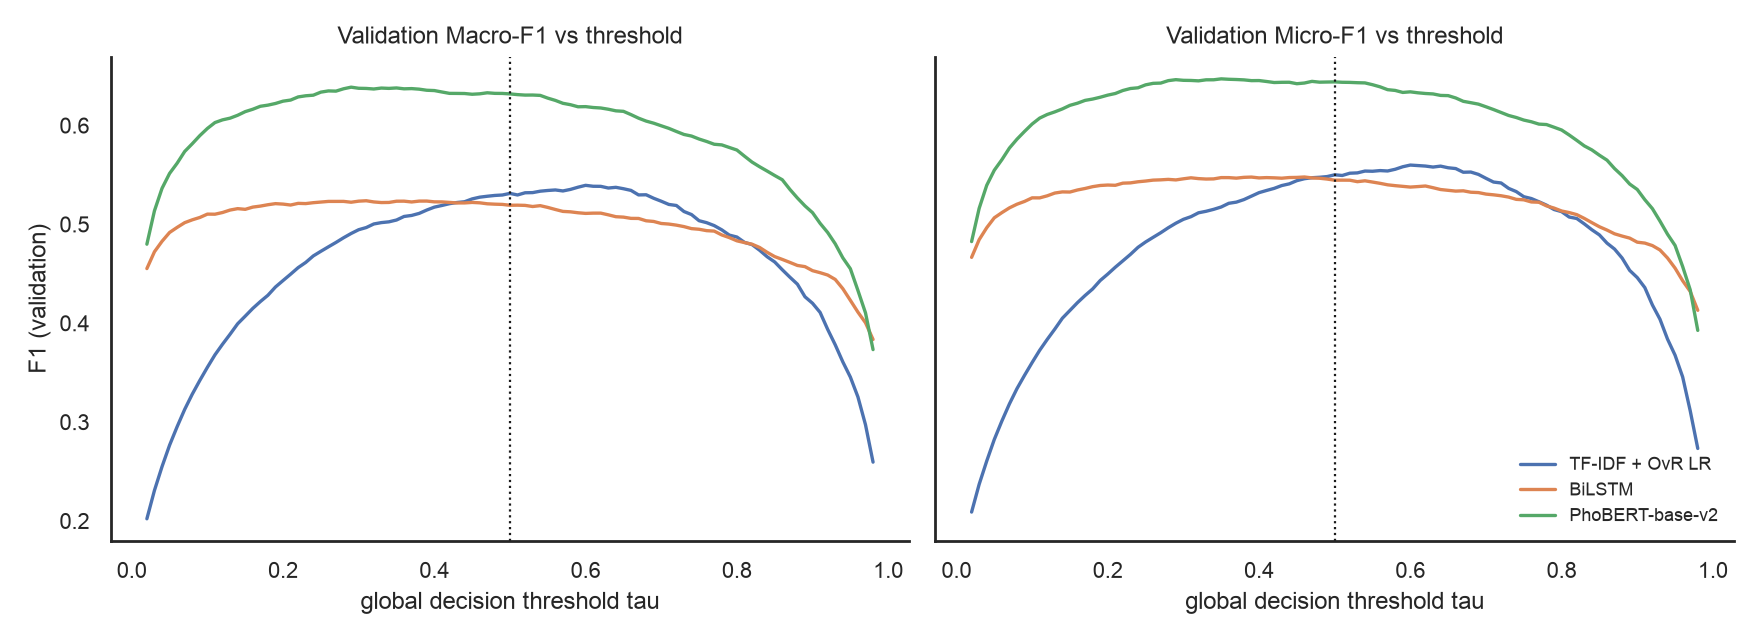

,model,val_macro_f1@0.5,val_micro_f1@0.5,best_global_tau(val),val_macro_f1@best,gain_vs_0.5,val_macro_f1@0.3,val_macro_f1@0.4,val_macro_f1@0.6,val_macro_f1@0.7,"range_macro_f1_tau_in_[0.3,0.7]"
0,TF-IDF + OvR LR,0.5313,0.5501,0.60,0.5395,0.0082,0.4946,0.5174,0.5395,0.5234,0.0449
1,BiLSTM,0.5193,0.5447,0.31,0.5239,0.0046,0.5235,0.5228,0.5111,0.5009,0.0230
2,PhoBERT-base-v2,0.6320,0.6441,0.29,0.6388,0.0068,0.6377,0.6354,0.6191,0.5997,0.0383
3,ViSoBERT,0.6095,0.6234,0.27,0.6171,0.0076,0.6170,0.6117,0.6040,0.5985,0.0187
4,ViSoBERT-14GB,0.6171,0.6327,0.38,0.6232,0.0061,0.6211,0.6230,0.6057,0.5854,0.0378
5,Ensemble (3),0.6409,0.6562,0.32,0.6548,0.0139,0.6539,0.6516,0.6217,0.5863,0.0685


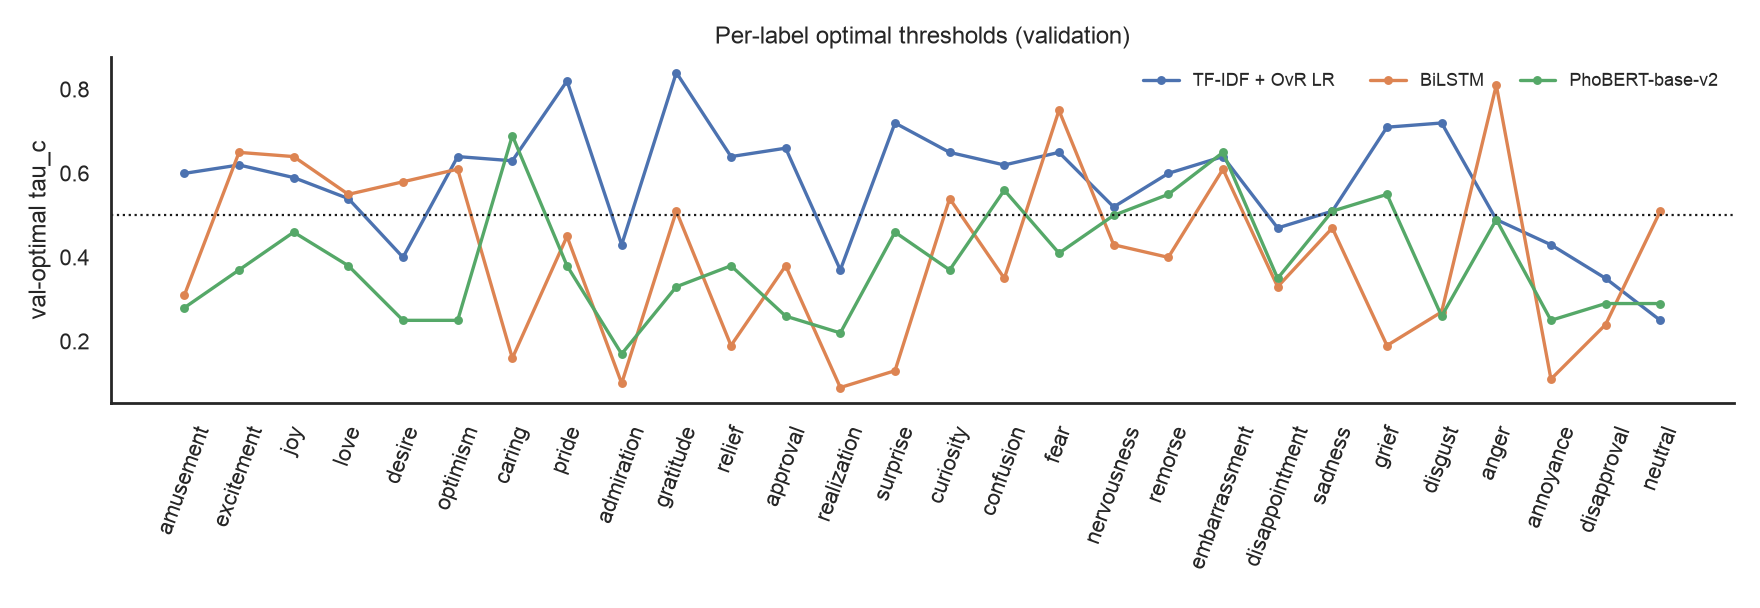

,model,run,strategy,tau,val_macro_f1,test_macro_f1,val_micro_f1,test_micro_f1,test_hamming_loss,gap_macro_f1(val-test)
0,TF-IDF + OvR LR,tfidf_lr,fixed,0.50,0.5313,0.5419,0.5501,0.5576,0.0665,-0.0106
1,TF-IDF + OvR LR,tfidf_lr,global,0.60,0.5395,0.5377,0.5600,0.5545,0.0596,0.0018
2,TF-IDF + OvR LR,tfidf_lr,per_label,per-label,0.5555,0.5395,0.5598,0.5458,0.0666,0.0160
3,BiLSTM,bilstm,fixed,0.50,0.5193,0.5122,0.5447,0.5330,0.0581,0.0071
4,BiLSTM,bilstm,global,0.31,0.5239,0.5238,0.5471,0.5412,0.0626,0.0001
5,BiLSTM,bilstm,per_label,per-label,0.5419,0.5178,0.5580,0.5336,0.0628,0.0241
6,PhoBERT-base-v2,phobert,fixed,0.50,0.6320,0.6292,0.6441,0.6461,0.0472,0.0028
7,PhoBERT-base-v2,phobert,global,0.29,0.6388,0.6330,0.6464,0.6454,0.0535,0.0058
8,PhoBERT-base-v2,phobert,per_label,per-label,0.6552,0.6336,0.6601,0.6474,0.0509,0.0216
9,ViSoBERT,visobert,fixed,0.50,0.6095,0.6133,0.6234,0.6316,0.0483,-0.0038


In [9]:
F("q5_threshold_sensitivity.png", 1000)
display(T("q5_threshold_sensitivity_summary.csv").round(4))
F("q5_per_label_thresholds.png", 1000)
display(T("threshold_strategies.csv").round(4))

## Head / mid / tail and cardinality breakdown (preview of the Final RQ1)

In [10]:
display(T("tier_and_cardinality_breakdown.csv").round(4))

,model,strategy,macro_f1_head,macro_f1_mid,macro_f1_tail,micro_f1_|Y|=1,micro_f1_|Y|=2,micro_f1_|Y|=3,micro_f1_|Y|>=4
0,TF-IDF + OvR LR,fixed,0.5674,0.5512,0.5061,0.4673,0.5616,0.6195,0.6275
1,TF-IDF + OvR LR,global,0.5575,0.5471,0.5075,0.4939,0.5506,0.6101,0.5841
2,TF-IDF + OvR LR,per_label,0.5630,0.5501,0.5042,0.4723,0.5524,0.5960,0.5858
3,BiLSTM,fixed,0.5394,0.5146,0.4824,0.5015,0.5312,0.5566,0.5707
4,BiLSTM,global,0.5522,0.5213,0.4983,0.4833,0.5343,0.5954,0.6063
5,BiLSTM,per_label,0.5442,0.5114,0.4986,0.4785,0.5404,0.5607,0.5864
6,PhoBERT-base-v2,fixed,0.6408,0.6526,0.5915,0.5696,0.6563,0.6892,0.6726
7,PhoBERT-base-v2,global,0.6440,0.6528,0.6000,0.5274,0.6591,0.7072,0.7505
8,PhoBERT-base-v2,per_label,0.6511,0.6512,0.5966,0.5413,0.6640,0.7028,0.7051
9,ViSoBERT,fixed,0.6392,0.6189,0.5812,0.5771,0.6390,0.6591,0.6580


## Error analysis (PhoBERT, test, tau = 0.5)

,label,support,false_negatives,false_positives,fn_rate(miss),fp_per_100
0,annoyance,343,145,101,0.423,4.89
1,amusement,374,105,59,0.281,2.85
2,disappointment,197,90,97,0.457,4.69
3,joy,204,80,77,0.392,3.73
4,anger,189,78,58,0.413,2.81
5,disapproval,112,77,45,0.688,2.18
6,disgust,141,75,57,0.532,2.76
7,neutral,116,71,52,0.612,2.52
8,sadness,345,70,131,0.203,6.34
9,realization,95,57,39,0.600,1.89


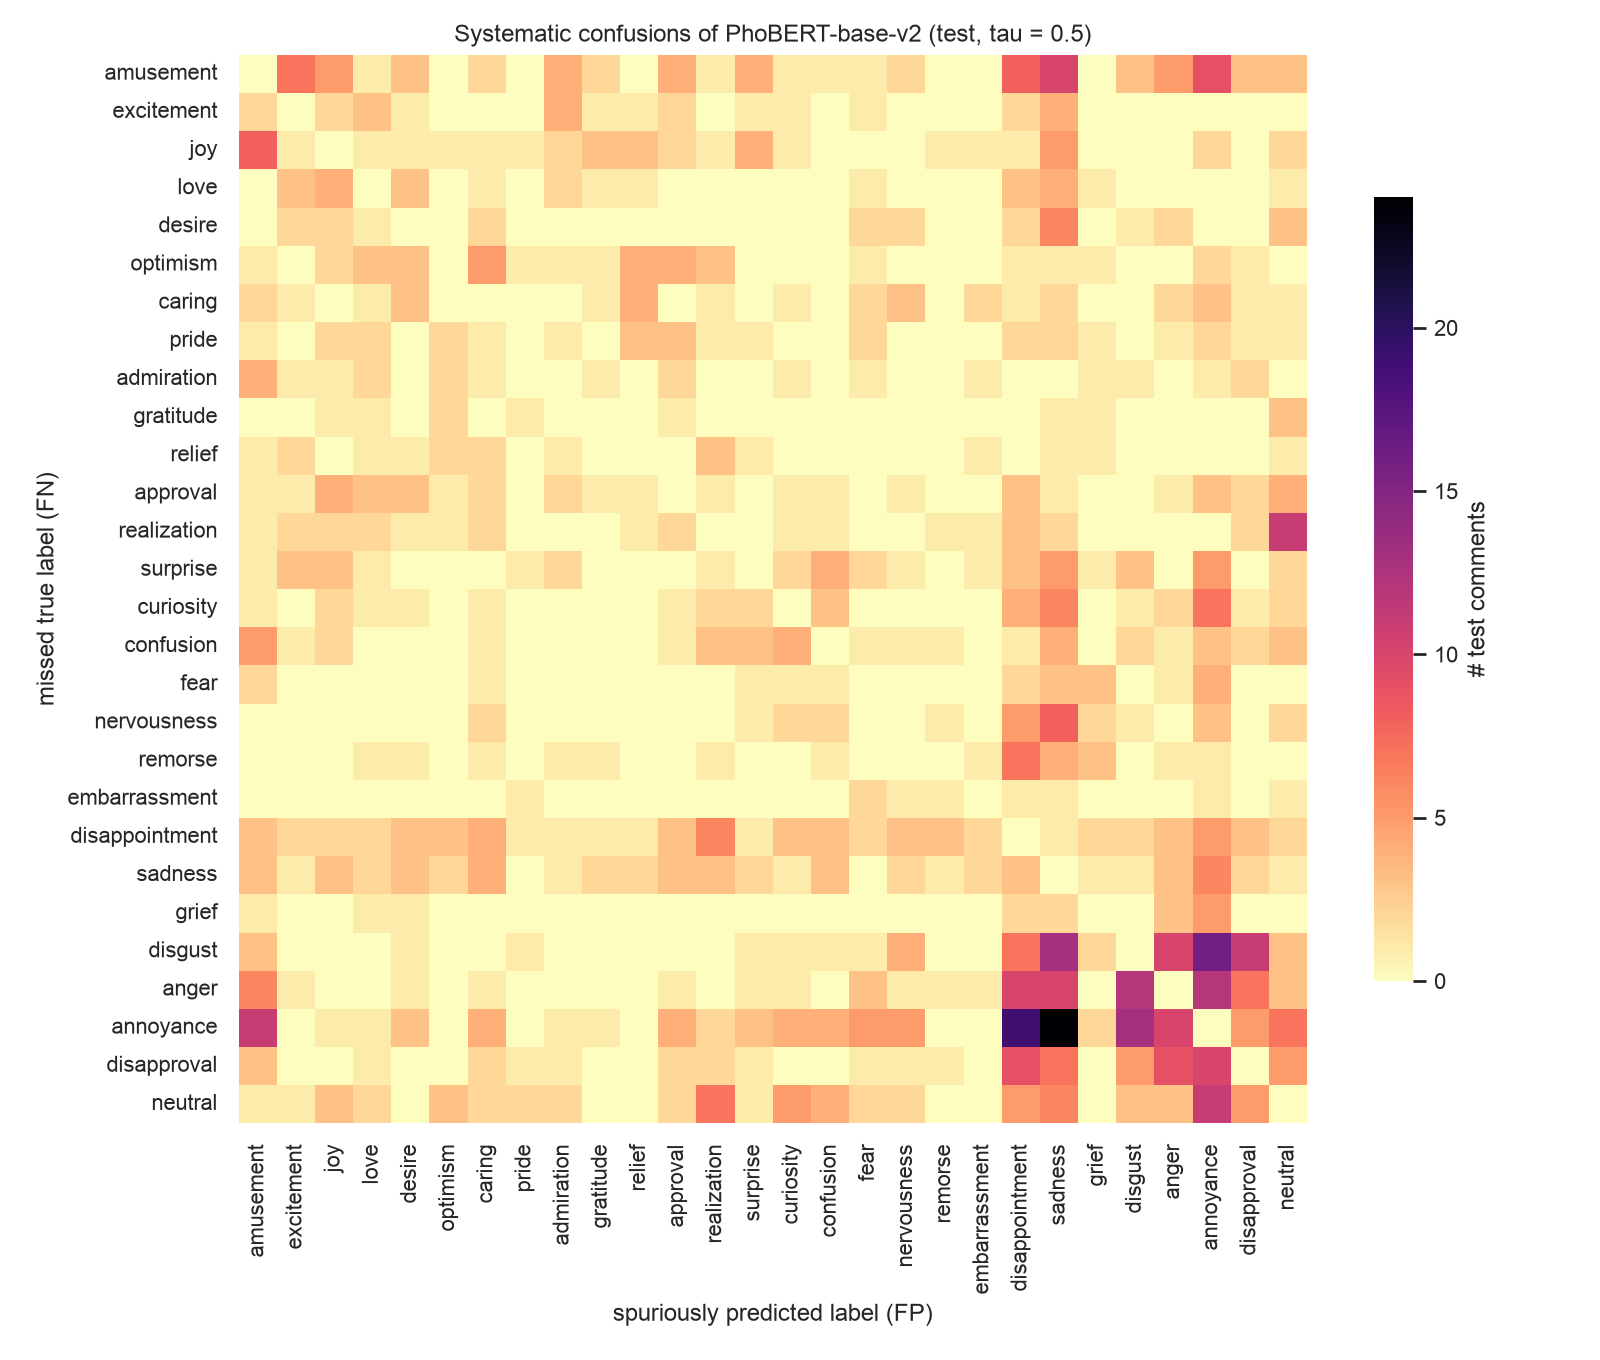

,missed_true_label,spurious_pred_label,count
0,annoyance,sadness,24
1,annoyance,disappointment,19
2,disgust,annoyance,16
3,annoyance,disgust,13
4,disgust,sadness,13
5,anger,annoyance,12
6,anger,disgust,12
7,neutral,annoyance,11
8,realization,neutral,11
9,annoyance,amusement,11


,bucket,n,exact_match,samples_f1,micro_f1,avg_FN_per_comment,avg_FP_per_comment,empty_prediction_rate
0,all,2067,0.294,0.628,0.646,0.701,0.620,0.031
1,style=short,337,0.448,0.700,0.703,0.451,0.490,0.027
2,style=long,283,0.198,0.600,0.622,0.887,0.767,0.018
3,style=emoji,536,0.308,0.663,0.665,0.660,0.659,0.015
4,style=emoji_heavy,180,0.333,0.702,0.704,0.611,0.622,0.017
5,style=emoticon,236,0.305,0.674,0.696,0.669,0.521,0.021
6,style=teencode,509,0.267,0.610,0.629,0.731,0.699,0.024
7,style=plain,793,0.259,0.602,0.631,0.749,0.618,0.042
8,|Y|=1,695,0.409,0.592,0.570,0.299,0.760,0.047
9,|Y|=2,946,0.276,0.637,0.656,0.728,0.604,0.027


,case_type,sample_id,style_buckets,true_labels,pred_labels,top4_probs,note
0,false_negative,3919,plain,"confusion, fear",(none),"neutral(0.41), curiosity(0.27), confusion(0.13...",missed fear (p=0.00)
1,false_negative,15999,short,"amusement, optimism",(none),"admiration(0.36), annoyance(0.30), disgust(0.2...",missed optimism (p=0.00)
2,false_negative,tik005017,short,caring,"anger, annoyance","anger(0.94), annoyance(0.69), disgust(0.15), d...",missed caring (p=0.00)
3,false_negative,609,plain,"amusement, relief",amusement,"amusement(0.98), excitement(0.49), curiosity(0...",missed relief (p=0.00)
4,false_negative,682,plain,"amusement, neutral","disgust, anger","anger(0.76), disgust(0.62), annoyance(0.50), s...",missed neutral (p=0.00)
5,false_negative,12013,teencode,amusement,sadness,"sadness(1.00), disappointment(0.40), caring(0....",missed amusement (p=0.00)
6,false_negative,tik013247,emoji,"disappointment, sadness",realization,"realization(0.78), remorse(0.49), confusion(0....",missed disappointment (p=0.00)
7,false_negative,20465,plain,approval,"nervousness, disappointment, sadness, annoyance","disappointment(0.82), sadness(0.82), annoyance...",missed approval (p=0.00)
8,false_negative,14149,plain,"curiosity, neutral",approval,"approval(0.78), caring(0.11), realization(0.09...",missed curiosity (p=0.00)
9,false_negative,4766,plain,"curiosity, disappointment, annoyance",curiosity,"curiosity(0.61), amusement(0.36), excitement(0...",missed disappointment (p=0.00)


In [11]:
display(T("error_by_label.csv"))
F("error_confusion_pairs.png", 750)
display(T("error_confusion_pairs.csv").head(20))
display(T("error_by_bucket.csv").round(3))
display(T("error_cases_public.csv").head(40))

Private audit with the comment text (local only, never publish):

In [12]:
SHOW_PRIVATE = False  # set True only on your own machine; never commit/share outputs containing raw text
p = "results/private/error_cases_with_text_phobert.csv"
if SHOW_PRIVATE and os.path.exists(p):
    display(pd.read_csv(p)[["case_type", "text", "true_labels", "pred_labels", "top4_probs"]].head(30))

## Comparison with the published baselines

In [13]:
display(T("comparison_with_paper.csv").round(4))

,model,decoding,test_macro_f1,test_micro_f1,source
0,"PhoBERT-base-v2 (paper, emoji kept)","tau=0.5, pos_weight BCE",0.5633,0.5740,Hung et al. (EACL 2026) official notebooks
1,"PhoBERT-base-v2 (paper, emoji->text)","tau=0.5, pos_weight BCE",0.5931,0.6042,Hung et al. (EACL 2026) official notebooks
2,CafeBERT (paper),"tau=0.5, pos_weight BCE",0.6117,0.6247,Hung et al. (EACL 2026) official notebooks
3,"ViSoBERT (paper, best)","tau=0.5, pos_weight BCE",0.6150,0.6346,Hung et al. (EACL 2026) official notebooks
4,TF-IDF + OvR LR (ours),tau=0.5,0.5419,0.5576,this work
5,TF-IDF + OvR LR (ours),per-label tau (val-tuned),0.5395,0.5458,this work
6,BiLSTM (ours),tau=0.5,0.5122,0.5330,this work
7,BiLSTM (ours),per-label tau (val-tuned),0.5178,0.5336,this work
8,PhoBERT-base-v2 (ours),tau=0.5,0.6292,0.6461,this work
9,PhoBERT-base-v2 (ours),per-label tau (val-tuned),0.6336,0.6474,this work
